In [21]:
#Cargar datos

import yfinance as yf 
import pandas as pd 
import warnings 
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.ar_model import AutoReg
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore') 

# Extracción de precios históricos en tres meses (2023)
disney = yf.download(tickers='dis', 
start="2023-01-01", 
end="2023-03-31", rounding = True) 
disney

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,DIS,DIS,DIS,DIS,DIS
Date,,,,,
2023-01-03,86.26,87.23,85.16,86.27,14997100
2023-01-04,89.18,89.93,86.64,87.26,14957200
2023-01-05,89.12,89.67,87.76,88.87,11622600
2023-01-06,91.06,91.81,88.54,89.84,9828100
2023-01-09,91.89,92.79,90.61,91.56,11675800
...,...,...,...,...,...
2023-03-24,91.22,92.11,90.19,91.92,9534600
2023-03-27,92.71,93.10,91.51,91.90,7487900


In [23]:
# Extracción de los datos


disney = yf.download(
    tickers='DIS',
    start="2023-01-01",
    end="2023-03-31",
    rounding=True,
    auto_adjust=False
)

# Obtener solamente el precio de cierre
if isinstance(disney.columns, pd.MultiIndex):
    precios = disney['Close']['DIS'].copy()
else:
    precios = disney['Close'].copy()

precios = pd.Series(precios).dropna()
precios.index = pd.to_datetime(precios.index)

print("Número de observaciones:", len(precios))
print("\nPrimeros datos:")
print(precios.head())

[*********************100%***********************]  1 of 1 completed

Número de observaciones: 61

Primeros datos:
Date
2023-01-03    88.97
2023-01-04    91.98
2023-01-05    91.92
2023-01-06    93.92
2023-01-09    94.77
Name: DIS, dtype: float64


In [25]:
# ============================================================
# 2. DIVISIÓN 70% ENTRENAMIENTO / 30% VALIDACIÓN
# ============================================================

n = len(precios)
n_train = int(n * 0.70)

train = precios.iloc[:n_train]
test = precios.iloc[n_train:]

print("\n========================================")
print("DIVISIÓN DE LOS DATOS")
print("========================================")
print("Total de observaciones:", n)
print("Entrenamiento (70%):", len(train))
print("Validación (30%):", len(test))
print("Fecha inicial entrenamiento:", train.index[0].date())
print("Fecha final entrenamiento:", train.index[-1].date())
print("Fecha inicial validación:", test.index[0].date())
print("Fecha final validación:", test.index[-1].date())



DIVISIÓN DE LOS DATOS
Total de observaciones: 61
Entrenamiento (70%): 42
Validación (30%): 19
Fecha inicial entrenamiento: 2023-01-03
Fecha final entrenamiento: 2023-03-03
Fecha inicial validación: 2023-03-06
Fecha final validación: 2023-03-30


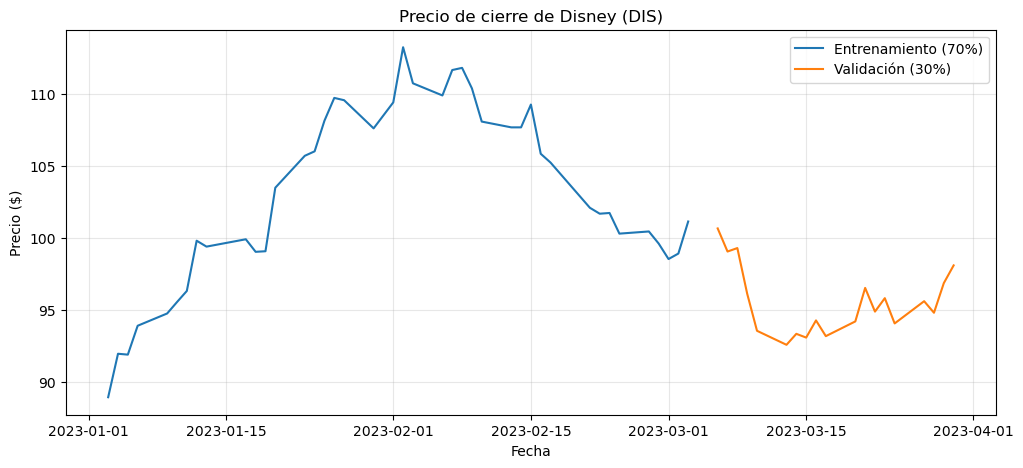

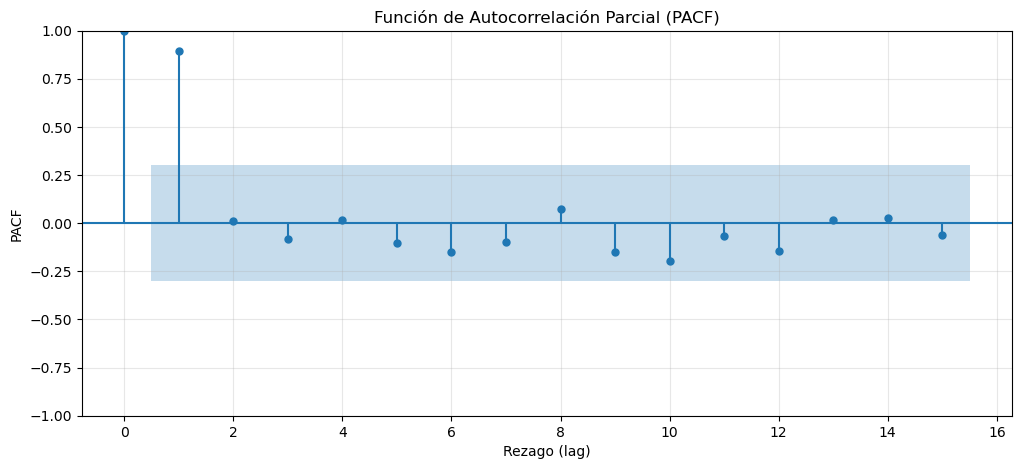

In [27]:
# 3. GRÁFICA DE LA SERIE
# ============================================================

plt.figure(figsize=(12,5))

plt.plot(train.index, train,
         label='Entrenamiento (70%)')

plt.plot(test.index, test,
         label='Validación (30%)')

plt.title('Precio de cierre de Disney (DIS)')
plt.xlabel('Fecha')
plt.ylabel('Precio ($)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ============================================================
# 4. GRÁFICA DE AUTOCORRELACIÓN PARCIAL (PACF)
# ============================================================

plt.figure(figsize=(12,5))

plot_pacf(
    train,
    lags=15,
    method='ywm',
    ax=plt.gca()
)

plt.title('Función de Autocorrelación Parcial (PACF)')
plt.xlabel('Rezago (lag)')
plt.ylabel('PACF')
plt.grid(alpha=0.3)
plt.show()

In [29]:
# ============================================================
# 5. PROBAR DIFERENTES MODELOS AR(p)
# ============================================================
# Se prueban modelos desde AR(1) hasta AR(15)

resultados = []

for p in range(1, 16):

    modelo = AutoReg(
        train,
        lags=p,
        trend='c',
        old_names=False
    ).fit()

    resultados.append({
        'p': p,
        'AIC': modelo.aic,
        'BIC': modelo.bic
    })

comparacion = pd.DataFrame(resultados)

print("\n========================================")
print("COMPARACIÓN DE MODELOS AR")
print("========================================")
print(comparacion.round(3))


COMPARACIÓN DE MODELOS AR
     p      AIC      BIC
0    1  162.738  167.879
1    2  160.879  167.635
2    3  158.890  167.208
3    4  157.960  167.786
4    5  154.399  165.675
5    6  150.536  163.204
6    7  148.463  162.461
7    8  146.591  161.854
8    9  142.234  158.696
9   10  134.653  152.241
10  11  124.212  142.854
11  12  115.643  135.260
12  13  112.412  132.922
13  14  110.580  131.895
14  15  107.221  129.251


In [31]:
# ============================================================
# 6. IDENTIFICAR LOS MEJORES MODELOS SEGÚN AIC Y BIC
# ============================================================

mejor_aic = comparacion.loc[
    comparacion['AIC'].idxmin()
]

mejor_bic = comparacion.loc[
    comparacion['BIC'].idxmin()
]

print("\n========================================")
print("MEJORES MODELOS")
print("========================================")

print(
    f"Mejor modelo según AIC: AR({int(mejor_aic['p'])}) "
    f"-> AIC = {mejor_aic['AIC']:.3f}"
)

print(
    f"Mejor modelo según BIC: AR({int(mejor_bic['p'])}) "
    f"-> BIC = {mejor_bic['BIC']:.3f}"
)


# ============================================================
# 7. SELECCIONAR EL MODELO
# ============================================================
# Si AIC y BIC coinciden, se utiliza ese modelo.
# Si no coinciden, se utiliza el modelo con menor BIC,
# debido a que BIC penaliza con mayor fuerza la complejidad.

if int(mejor_aic['p']) == int(mejor_bic['p']):
    p_optimo = int(mejor_aic['p'])
else:
    p_optimo = int(mejor_bic['p'])

print("\n========================================")
print("MODELO SELECCIONADO")
print("========================================")
print(f"Modelo autorregresivo seleccionado: AR({p_optimo})")


MEJORES MODELOS
Mejor modelo según AIC: AR(15) -> AIC = 107.221
Mejor modelo según BIC: AR(15) -> BIC = 129.251

MODELO SELECCIONADO
Modelo autorregresivo seleccionado: AR(15)


In [33]:
# ============================================================
# 8. AJUSTAR EL MODELO CON EL 70% DE ENTRENAMIENTO
# ============================================================

modelo_ar = AutoReg(
    train,
    lags=p_optimo,
    trend='c',
    old_names=False
).fit()

print("\nResumen del modelo:")
print(modelo_ar.summary())


# ============================================================
# 9. PRONÓSTICO SOBRE EL 30% DE VALIDACIÓN
# ============================================================

pred_test = modelo_ar.predict(
    start=len(train),
    end=len(precios)-1,
    dynamic=False
)

pred_test.index = test.index



Resumen del modelo:
                            AutoReg Model Results                             
Dep. Variable:                    DIS   No. Observations:                   42
Model:                    AutoReg(15)   Log Likelihood                 -36.611
Method:               Conditional MLE   S.D. of innovations              0.939
Date:                Sat, 26 Sep 2026   AIC                            107.221
Time:                        18:46:10   BIC                            129.251
Sample:                            15   HQIC                           113.772
                                   42                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         72.7273     16.420      4.429      0.000      40.544     104.910
DIS.L1         0.4497      0.197      2.281      0.023       0.063       0.836
DIS.L2        -0.2051      0.21

In [35]:
# ============================================================
# 10. INDICADORES DE BONDAD DE AJUSTE
# ============================================================

mae = mean_absolute_error(test, pred_test)

rmse = np.sqrt(
    mean_squared_error(test, pred_test)
)

mape = np.mean(
    np.abs((test - pred_test) / test)
) * 100

r2 = r2_score(test, pred_test)


print("\n========================================")
print("INDICADORES DE BONDAD DE AJUSTE")
print("========================================")

print(f"MAE  = {mae:.4f}")
print(f"RMSE = {rmse:.4f}")
print(f"MAPE = {mape:.2f}%")
print(f"R²   = {r2:.4f}")


# ============================================================
# 11. COMPARACIÓN ENTRE VALORES REALES Y PRONOSTICADOS
# ============================================================

comparacion_test = pd.DataFrame({
    'Real': test,
    'Pronosticado': pred_test
})

print("\n========================================")
print("VALIDACIÓN")
print("========================================")

print(comparacion_test.round(2))


INDICADORES DE BONDAD DE AJUSTE
MAE  = 8.1739
RMSE = 8.8958
MAPE = 8.61%
R²   = -14.4158

VALIDACIÓN
              Real  Pronosticado
Date                            
2023-03-06  100.66         98.71
2023-03-07   99.06         97.61
2023-03-08   99.30         97.46
2023-03-09   96.14         99.13
2023-03-10   93.57        101.90
2023-03-13   92.60        100.99
2023-03-14   93.36        100.47
2023-03-15   93.10        101.53
2023-03-16   94.29        103.35
2023-03-17   93.20        103.18
2023-03-20   94.22        104.05
2023-03-21   96.54        104.00
2023-03-22   94.90        105.24
2023-03-23   95.83        106.80
2023-03-24   94.08        106.57
2023-03-27   95.62        107.58
2023-03-28   94.82        107.66
2023-03-29   96.87        107.51
2023-03-30   98.10        107.35


In [39]:
# ============================================================
# 12. REAJUSTAR EL MODELO CON TODOS LOS DATOS
# ============================================================
# Una vez seleccionado y validado el modelo, utilizamos
# todos los datos disponibles de enero-marzo para generar
# el pronóstico de abril.

modelo_final = AutoReg(
    precios,
    lags=p_optimo,
    trend='c',
    old_names=False
).fit()


# ============================================================
# 13. PRONÓSTICO DE ABRIL DE 2023
# ============================================================

# Días hábiles de abril de 2023
fechas_abril = pd.bdate_range(
    start='2023-04-01',
    end='2023-04-30'
)

num_dias_abril = len(fechas_abril)

pronostico = modelo_final.get_prediction(
    start=len(precios),
    end=len(precios) + num_dias_abril - 1
)

pred_abril = pronostico.predicted_mean
intervalo = pronostico.conf_int(alpha=0.10)

pred_abril.index = fechas_abril
intervalo.index = fechas_abril


In [41]:
# ============================================================
# 14. TABLA DEL PRONÓSTICO
# ============================================================

pronosticos_abril = pd.DataFrame({
    'Precio pronosticado': pred_abril,
    'Límite inferior 90%': intervalo.iloc[:, 0],
    'Límite superior 90%': intervalo.iloc[:, 1]
})

print("\n========================================")
print("PRONÓSTICO DE PRECIOS - ABRIL 2023")
print("========================================")

print(pronosticos_abril.round(2))



PRONÓSTICO DE PRECIOS - ABRIL 2023
            Precio pronosticado  Límite inferior 90%  Límite superior 90%
2023-04-03                99.97                97.89               102.05
2023-04-04               101.51                98.68               104.34
2023-04-05               100.86                97.52               104.20
2023-04-06               102.85                99.31               106.39
2023-04-07               102.28                98.53               106.02
2023-04-10               103.81                99.90               107.72
2023-04-11               103.42                99.40               107.43
2023-04-12               104.40               100.30               108.49
2023-04-13               104.95               100.78               109.13
2023-04-14               105.48               101.02               109.94
2023-04-17               106.64               102.07               111.20
2023-04-18               106.33               101.62               111.03
20

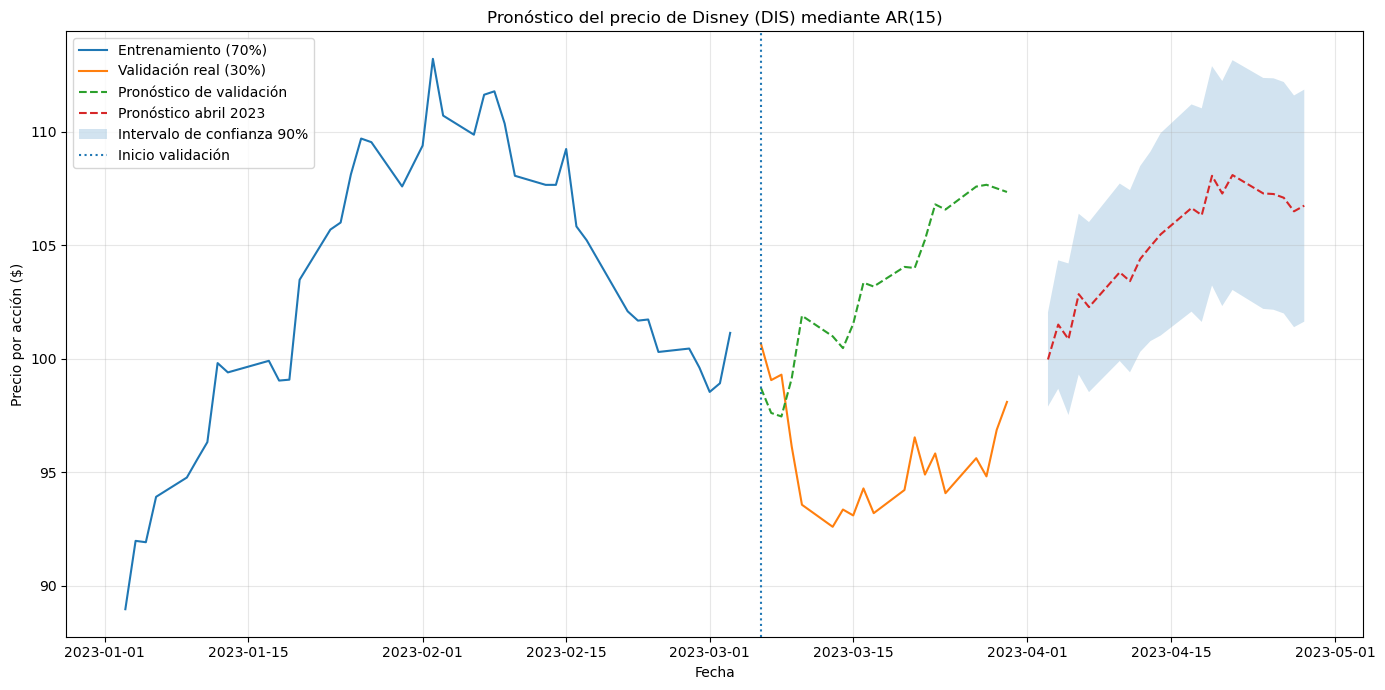

In [43]:

# ============================================================
# 15. GRÁFICA FINAL
# ============================================================

plt.figure(figsize=(14,7))

# Datos de entrenamiento
plt.plot(
    train.index,
    train,
    label='Entrenamiento (70%)'
)

# Datos de validación reales
plt.plot(
    test.index,
    test,
    label='Validación real (30%)'
)

# Pronóstico durante validación
plt.plot(
    pred_test.index,
    pred_test,
    linestyle='--',
    label='Pronóstico de validación'
)

# Pronóstico de abril
plt.plot(
    pred_abril.index,
    pred_abril,
    linestyle='--',
    label='Pronóstico abril 2023'
)

# Intervalo de confianza 90%
plt.fill_between(
    pred_abril.index,
    intervalo.iloc[:, 0],
    intervalo.iloc[:, 1],
    alpha=0.2,
    label='Intervalo de confianza 90%'
)

plt.axvline(
    x=test.index[0],
    linestyle=':',
    label='Inicio validación'
)

plt.title(
    f'Pronóstico del precio de Disney (DIS) mediante AR({p_optimo})'
)

plt.xlabel('Fecha')
plt.ylabel('Precio por acción ($)')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [45]:
# ============================================================
# 16. CONCLUSIÓN AUTOMÁTICA
# ============================================================

print("\n========================================")
print("CONCLUSIÓN DEL ANÁLISIS")
print("========================================")

print(
    f"""
El análisis se realizó utilizando el 70% de los datos como
base de entrenamiento y el 30% restante como validación.

La gráfica PACF permitió identificar los rezagos con mayor
relación parcial con el precio.

Posteriormente se compararon modelos AR(1) hasta AR(15)
mediante los criterios AIC y BIC.

El modelo seleccionado fue AR({p_optimo}), utilizando como
criterio principal el BIC cuando AIC y BIC no coincidieron.

Durante la validación se obtuvo:

MAE  = {mae:.4f}
RMSE = {rmse:.4f}
MAPE = {mape:.2f}%
R²   = {r2:.4f}

El modelo fue posteriormente reajustado utilizando todos
los datos disponibles de enero a marzo de 2023 y se utilizó
para generar el pronóstico puntual de abril de 2023 junto
con un intervalo de confianza del 90%.

Los indicadores de validación permiten evaluar el desempeño
del modelo sobre datos que no fueron utilizados para ajustar
el modelo, por lo que son una referencia más útil para
estimar su capacidad de pronóstico que el AIC o el BIC por
sí solos.
"""
)


CONCLUSIÓN DEL ANÁLISIS

El análisis se realizó utilizando el 70% de los datos como
base de entrenamiento y el 30% restante como validación.

La gráfica PACF permitió identificar los rezagos con mayor
relación parcial con el precio.

Posteriormente se compararon modelos AR(1) hasta AR(15)
mediante los criterios AIC y BIC.

El modelo seleccionado fue AR(15), utilizando como
criterio principal el BIC cuando AIC y BIC no coincidieron.

Durante la validación se obtuvo:

MAE  = 8.1739
RMSE = 8.8958
MAPE = 8.61%
R²   = -14.4158

El modelo fue posteriormente reajustado utilizando todos
los datos disponibles de enero a marzo de 2023 y se utilizó
para generar el pronóstico puntual de abril de 2023 junto
con un intervalo de confianza del 90%.

Los indicadores de validación permiten evaluar el desempeño
del modelo sobre datos que no fueron utilizados para ajustar
el modelo, por lo que son una referencia más útil para
estimar su capacidad de pronóstico que el AIC o el BIC por
sí solos.

